# Model Comparison and Evaluation Synthesis
**Project:** Flexibility versus Interpretability in High-Dimensional Multiclass Cancer Classification from RNA-Seq Data  
**Authors:** Rajveer Vora, Amartya Amritanshu, P. Sanjith Reddy  
**Dataset:** TCGA Pan-Cancer RNA-Seq ( = 801, p = 20,531$, 5 Tumor Classes)

This notebook synthesizes the cross-validated results across all models evaluated on **10 repeated, identical stratified 80/20 train/test splits** ({train}=640, N_{test}=161$) with zero data leakage.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RESULTS_DIR = Path('../results')
FIGURES_DIR = Path('../reports/figures')
TABLES_DIR = Path('../reports/tables')


## 1. Main Model Comparison Table
Paired cross-validated metrics across the 10 repeated splits (=1000$).


In [2]:
main_df = pd.read_csv(RESULTS_DIR / 'main_model_comparison.csv')
summary = main_df.groupby(['category', 'model']).agg({
    'accuracy': ['mean', 'std'],
    'macro_f1': ['mean', 'std'],
    'log_loss': ['mean', 'std'],
    'active_features': ['mean'],
    'fit_time_s': ['mean', 'std'],
}).round(4)
summary


accuracy         macro_f1  \
                                                     mean     std     mean   
category                            model                                    
Linear                              ElasticNet     0.9981  0.0030   0.9984   
                                    Lasso          0.9950  0.0049   0.9959   
                                    Ridge          0.9981  0.0030   0.9984   
                                    Softmax        0.9981  0.0030   0.9984   
Neural Network (Dense)              PCA_MLP        0.9975  0.0043   0.9974   
Neural Network (Sparse Group-Lasso) Sparse_NN      0.9981  0.0042   0.9984   
Tree Ensemble                       RandomForest   0.9944  0.0054   0.9954   
                                    XGBoost        0.9981  0.0030   0.9979   

                                                         log_loss          \
                                                     std     mean     std   
category                            model                                   
Linear                              ElasticNet    0.0026   0.0200  0.0063   
                                    Lasso         0.0041   0.0299  0.0084   
                                    Ridge         0.0026   0.0048  0.0052   
                                    Softmax       0.0026   0.0048  0.0053   
Neural Network (Dense)              PCA_MLP       0.0044   0.0044  0.0056   
Neural Network (Sparse Group-Lasso) Sparse_NN     0.0036   0.0075  0.0162   
Tree Ensemble                       RandomForest  0.0046   0.0813  0.0113   
                                    XGBoost       0.0035   0.0161  0.0083   

                                                 active_features fit_time_s  \
                                                            mean       mean   
category                            model                                     
Linear                              ElasticNet             217.5     3.3224   
                                    Lasso                   88.9     4.4378   
                                    Ridge                 1000.0     0.0037   
                                    Softmax               1000.0     0.0045   
Neural Network (Dense)              PCA_MLP                434.2     1.6811   
Neural Network (Sparse Group-Lasso) Sparse_NN             1000.0     1.3056   
Tree Ensemble                       RandomForest          1000.0     0.1319   
                                    XGBoost               1000.0     2.2695   

                                                          
                                                     std  
category                            model                 
Linear                              ElasticNet    0.1698  
                                    Lasso         0.2979  
                                    Ridge         0.0007  
                                    Softmax       0.0015  
Neural Network (Dense)              PCA_MLP       0.7671  
Neural Network (Sparse Group-Lasso) Sparse_NN     0.0856  
Tree Ensemble                       RandomForest  0.0067  
                                    XGBoost       0.0833

## 2. Feature Selection Stability Analysis
Pairwise Jaccard and Dice similarity across the 10 splits.


In [3]:
stab_df = pd.read_csv(RESULTS_DIR / 'feature_stability.csv')
stab_df[['model', 'mean_feature_count', 'mean_jaccard', 'std_jaccard', 'mean_dice', 'std_dice']].round(4)


,model,mean_feature_count,mean_jaccard,std_jaccard,mean_dice,std_dice
0,Lasso,88.9,0.7398,0.0509,0.8495,0.0328
1,ElasticNet,217.5,0.7733,0.0410,0.8715,0.0260
2,RandomForest,50.0,0.2422,0.0519,0.3871,0.0687
3,XGBoost,50.0,0.4667,0.0442,0.6351,0.0413
4,Sparse_NN,1000.0,0.9539,0.0040,0.9764,0.0021


## 3. Sample Efficiency (569XStress) Stress Test
Macro-F1 across subsampled training sizes ({train} \in [30, 60, 120, 250, 640]$).


In [4]:
n_df = pd.read_csv(RESULTS_DIR / 'n_efficiency_comparison.csv')
n_pvt = n_df.pivot_table(index='model', columns='n_train', values='macro_f1', aggfunc=['mean', 'std']).round(3)
n_pvt


mean                                std                       \
n_train         30     60     120    250    640    30     60     120    250   
model                                                                         
ElasticNet    0.995  0.994  0.996  0.996  0.998  0.004  0.004  0.004  0.004   
Lasso         0.992  0.993  0.996  0.995  0.996  0.006  0.003  0.004  0.004   
RandomForest  0.990  0.996  0.995  0.995  0.996  0.009  0.004  0.004  0.004   
Ridge         0.995  0.998  0.998  0.998  0.998  0.000  0.003  0.003  0.003   
Softmax       0.999  0.997  0.998  0.998  0.998  0.002  0.003  0.003  0.003   
XGBoost       0.976  0.986  0.993  0.998  0.999  0.018  0.002  0.008  0.005   

                     
n_train         640  
model                
ElasticNet    0.003  
Lasso         0.004  
RandomForest  0.002  
Ridge         0.003  
Softmax       0.003  
XGBoost       0.002

## 4. Key Publication Visualizations


=== 01_class_balance.png ===


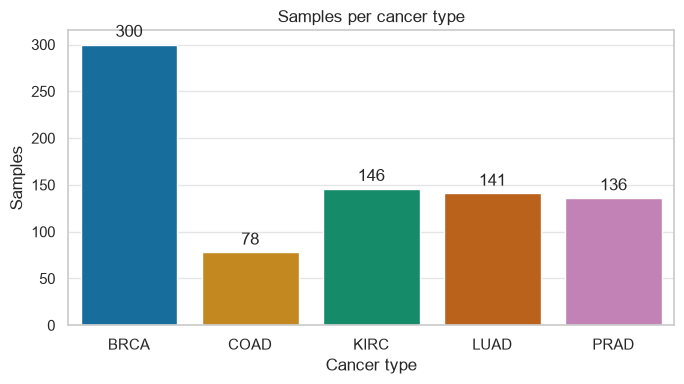

=== 01_model_comparison_boxplots.png ===


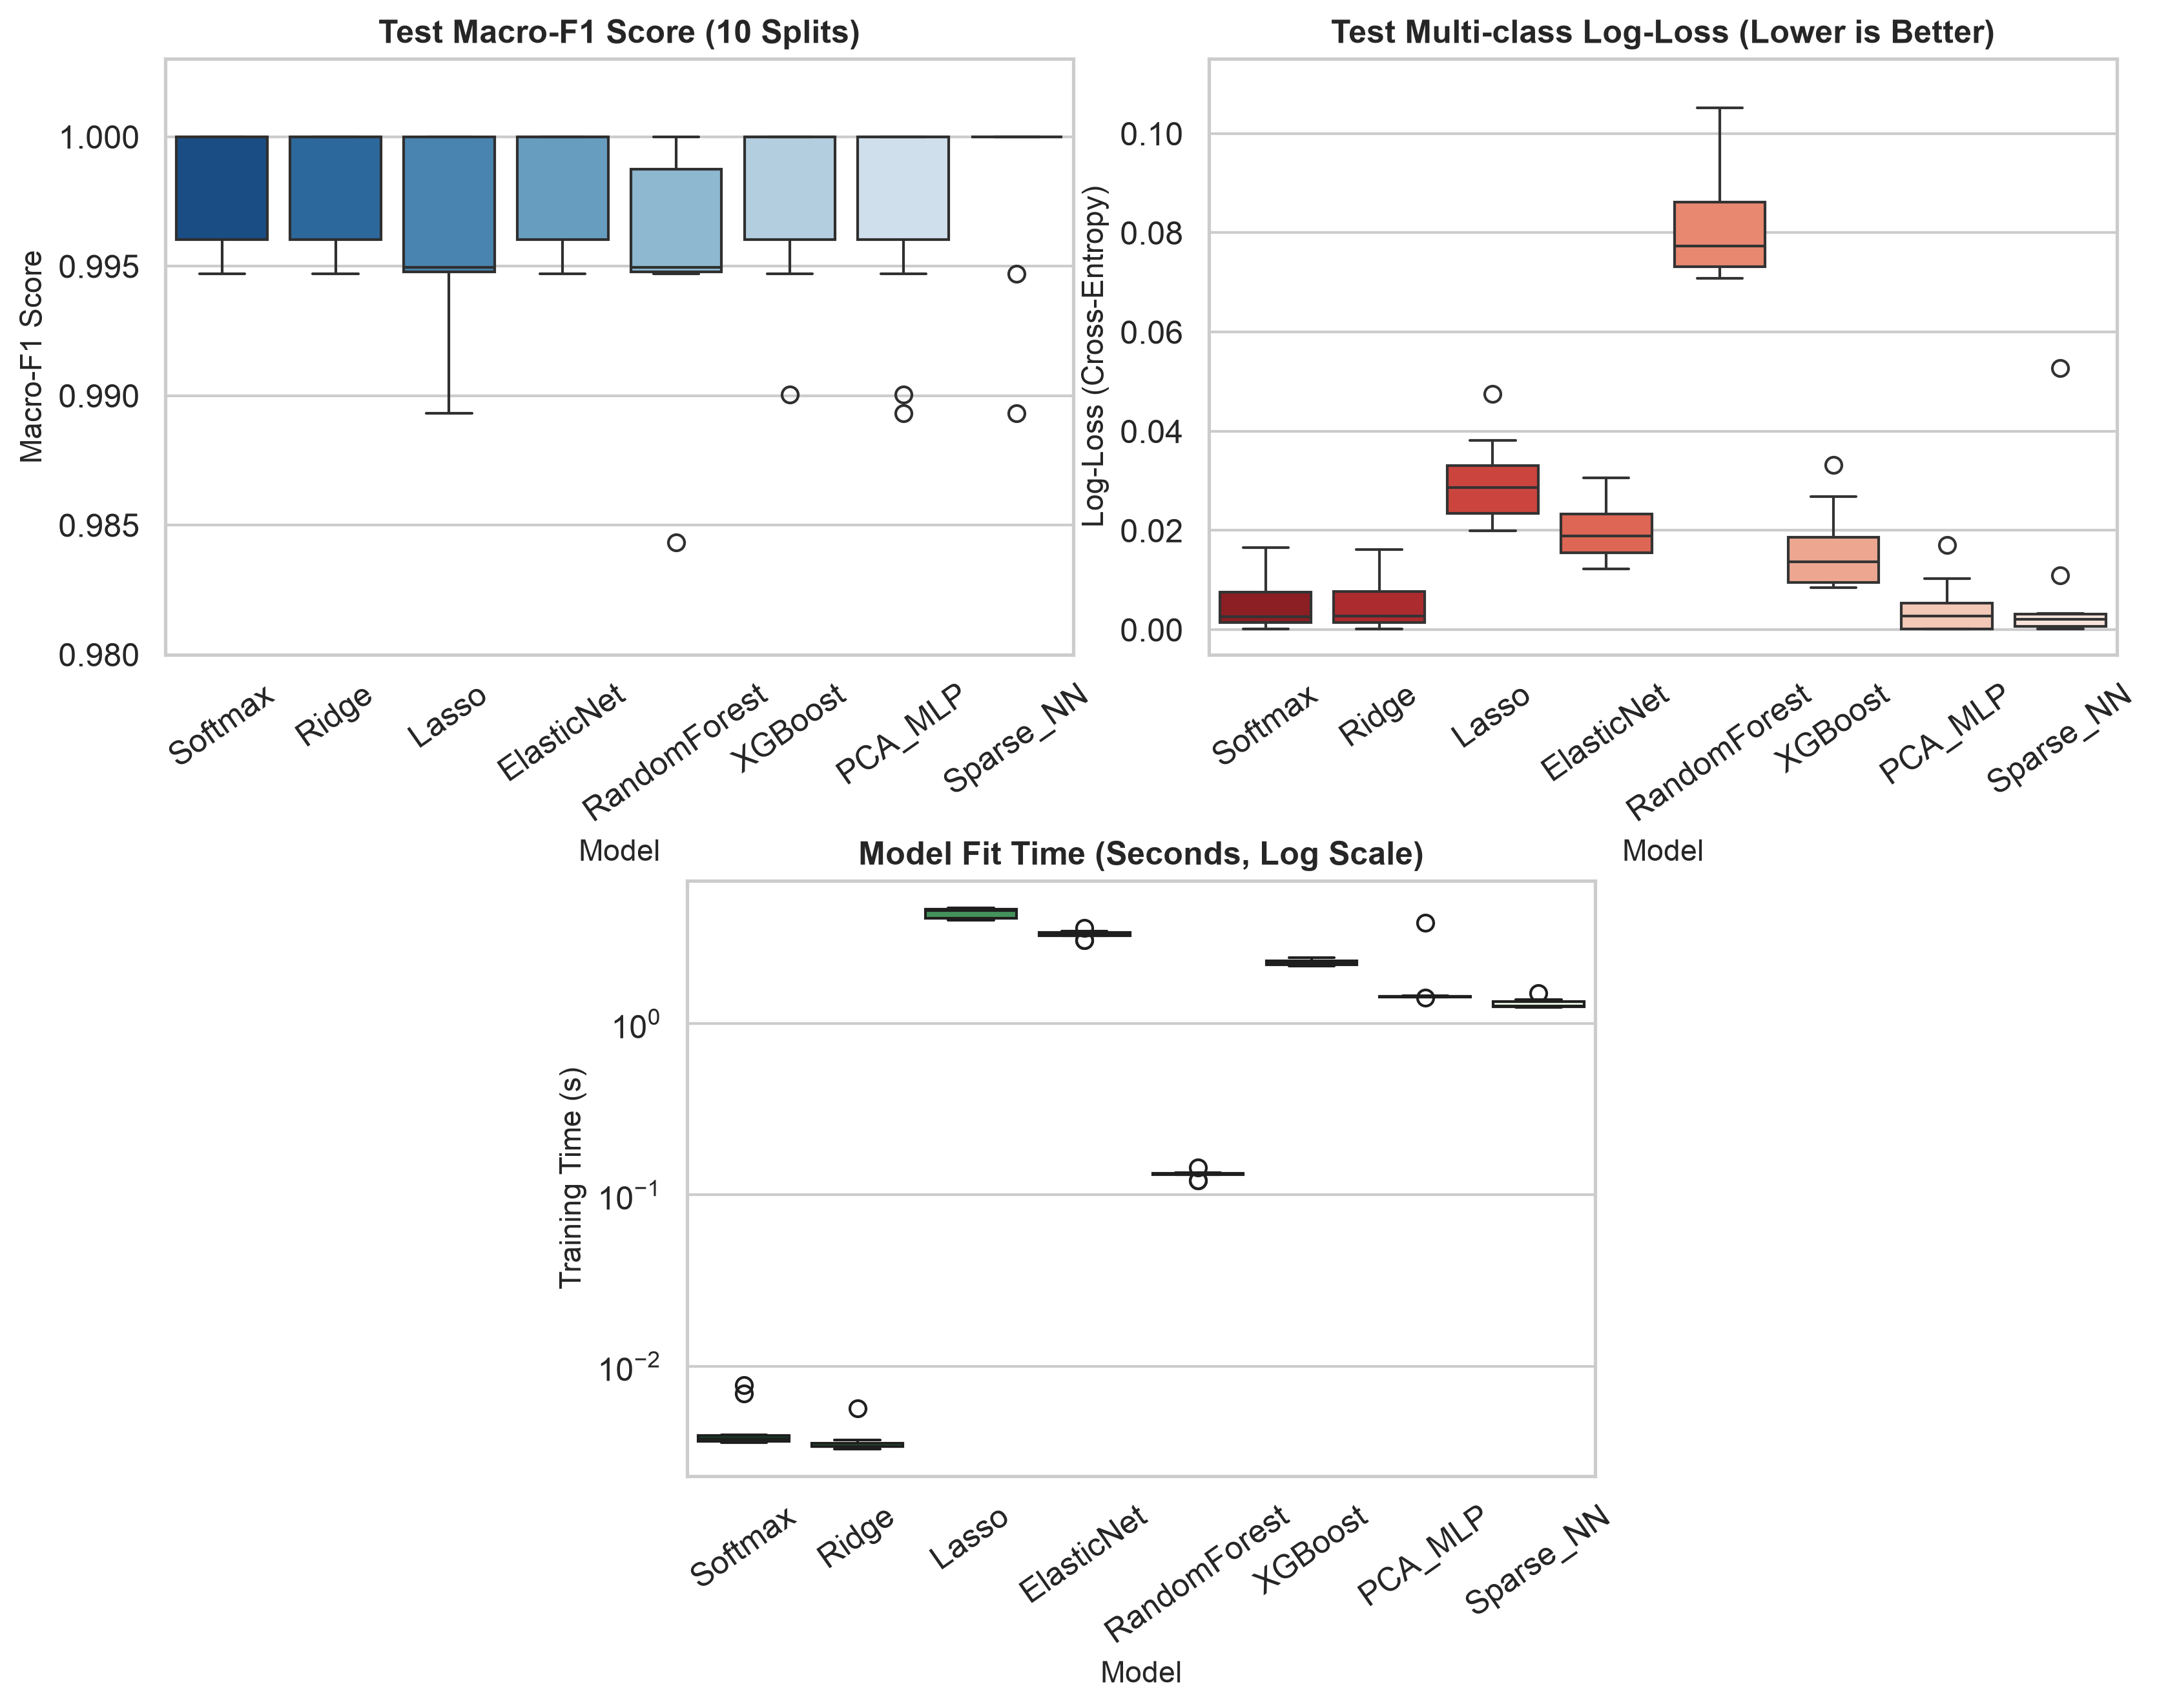

=== 02_n_efficiency_curves.png ===


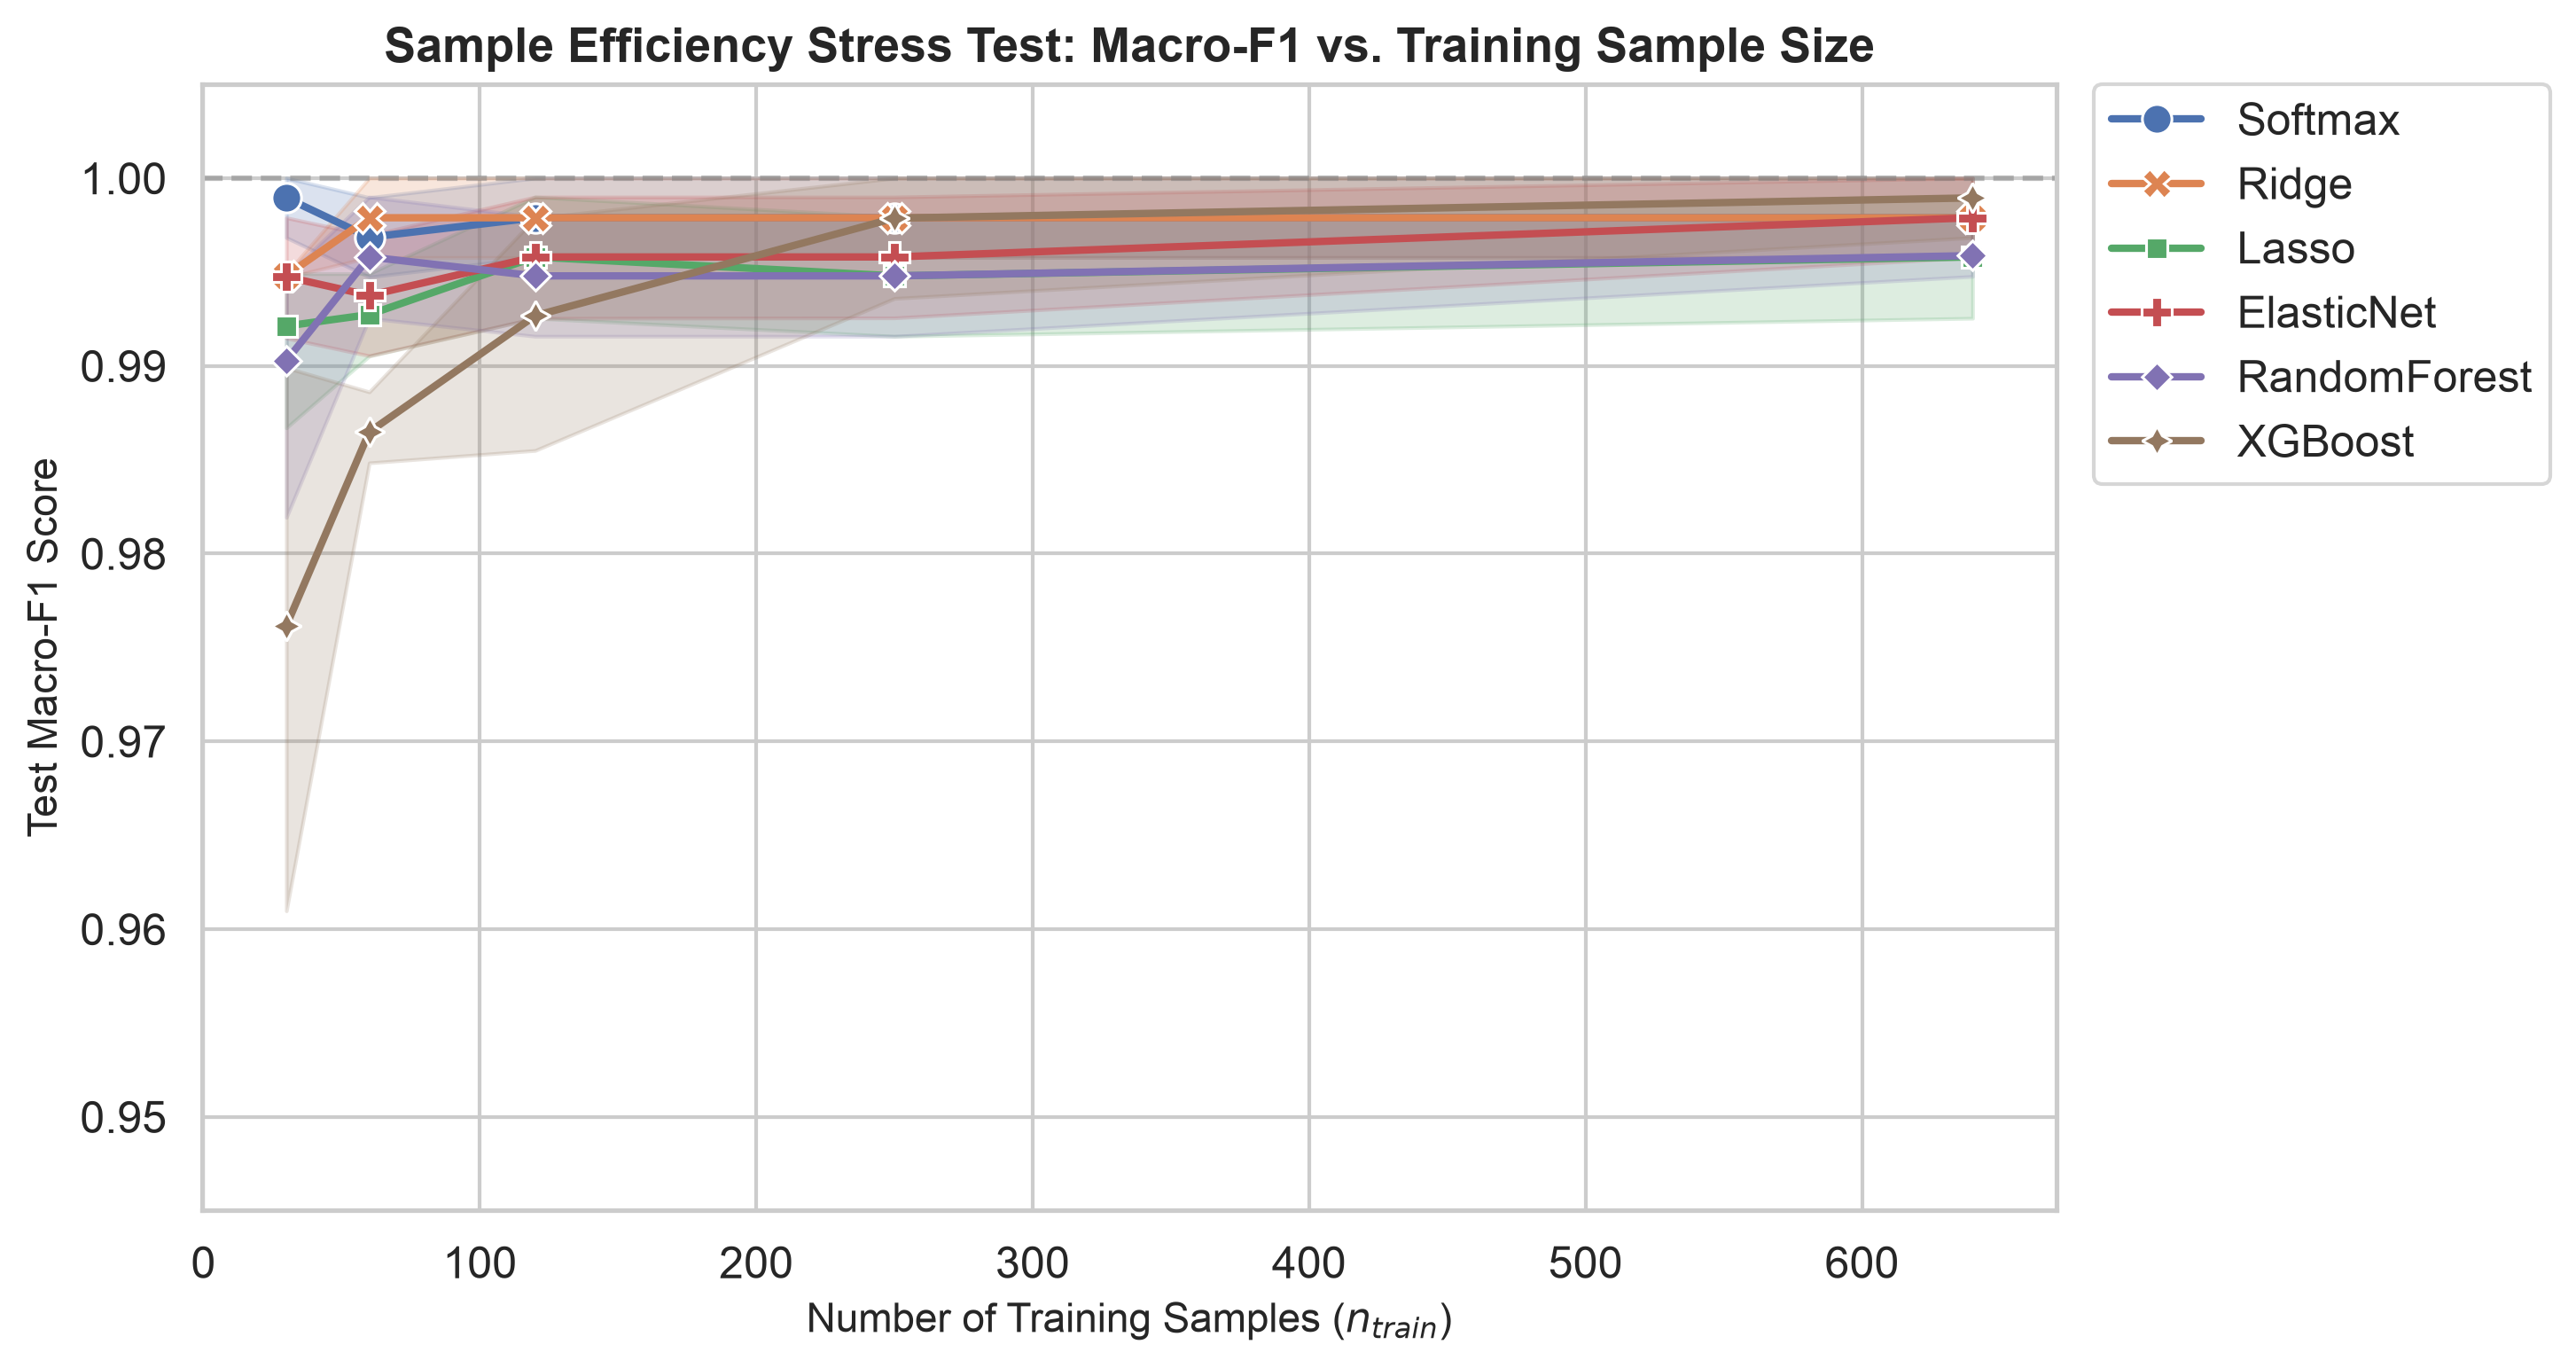

=== 02_sample_qc_by_class.png ===


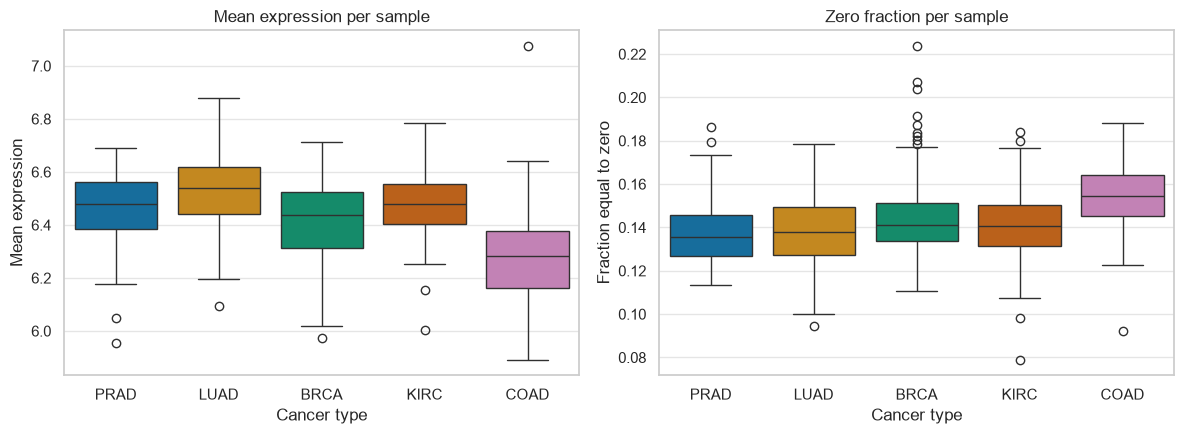

=== 03_gene_mean_variance.png ===


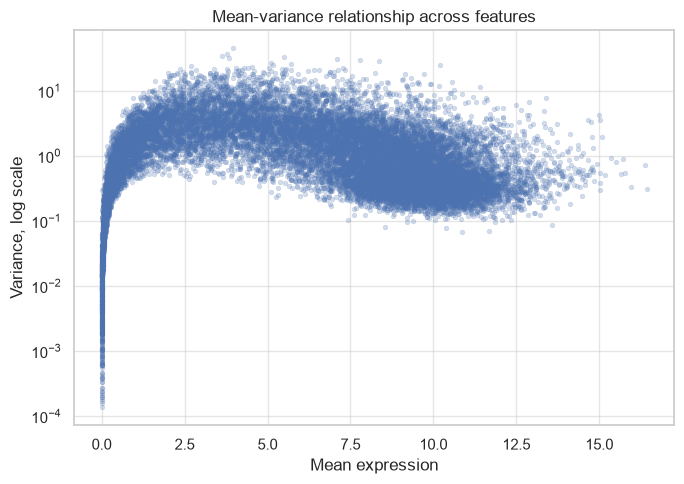

=== 04_feature_stability_barplot.png ===


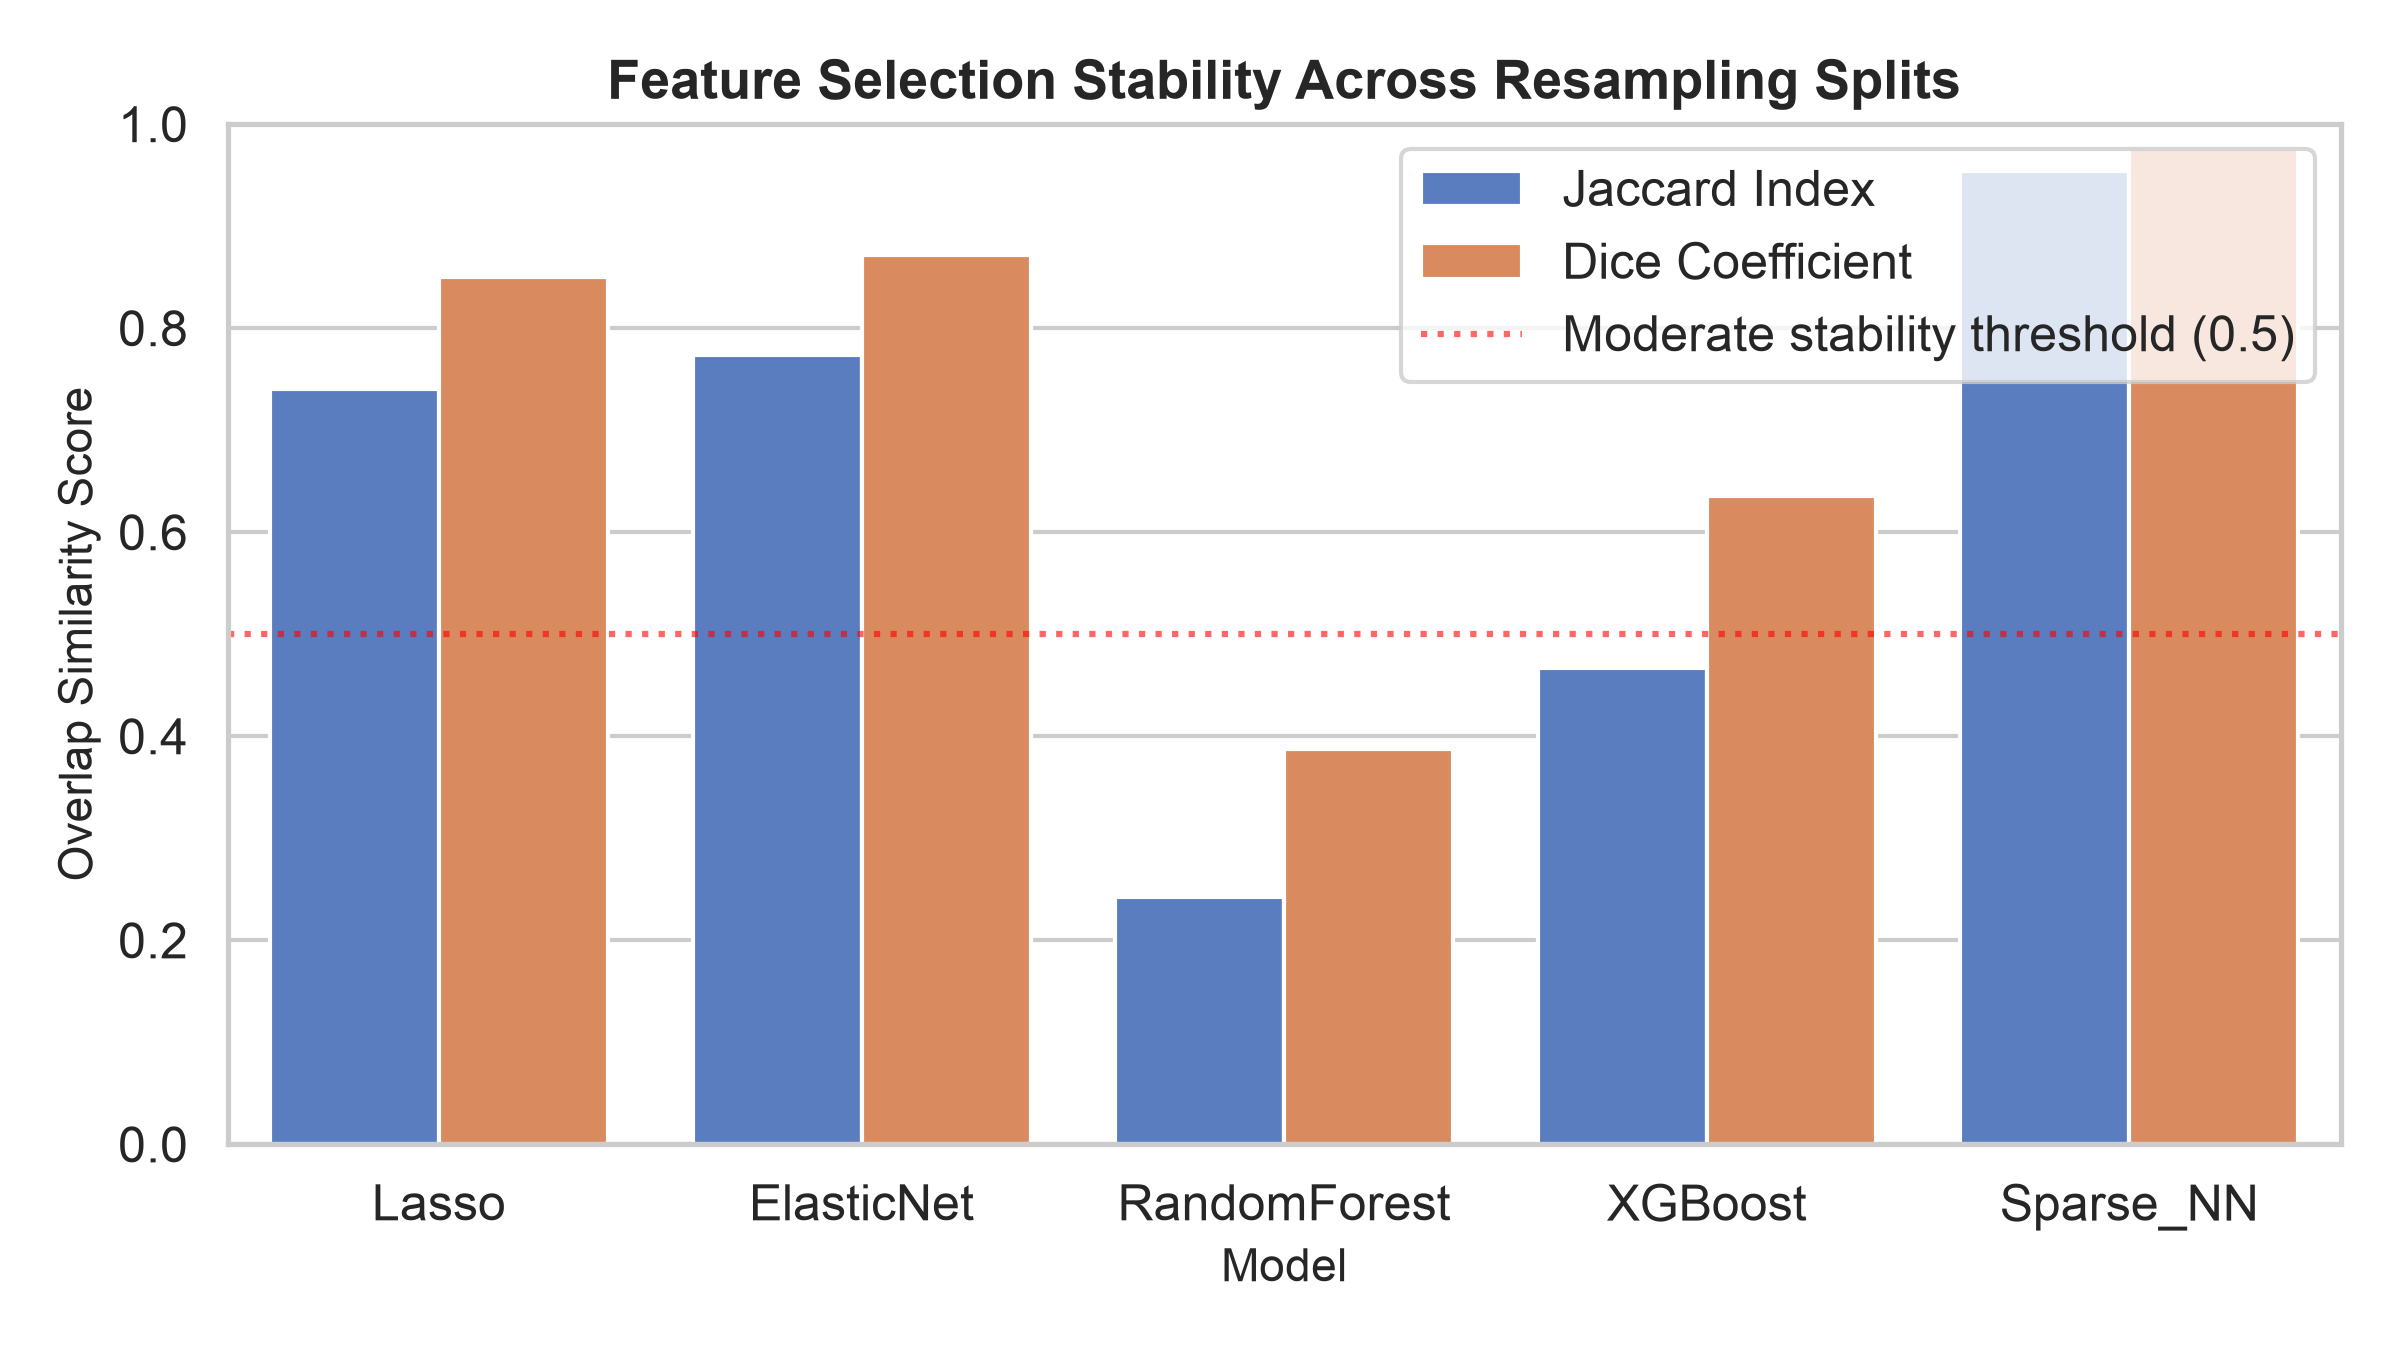

=== 04_pca_variance_explained.png ===


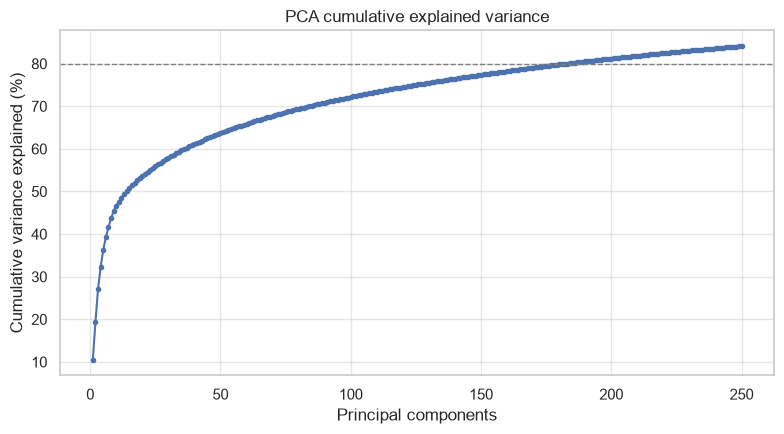

=== 05_pareto_frontier.png ===


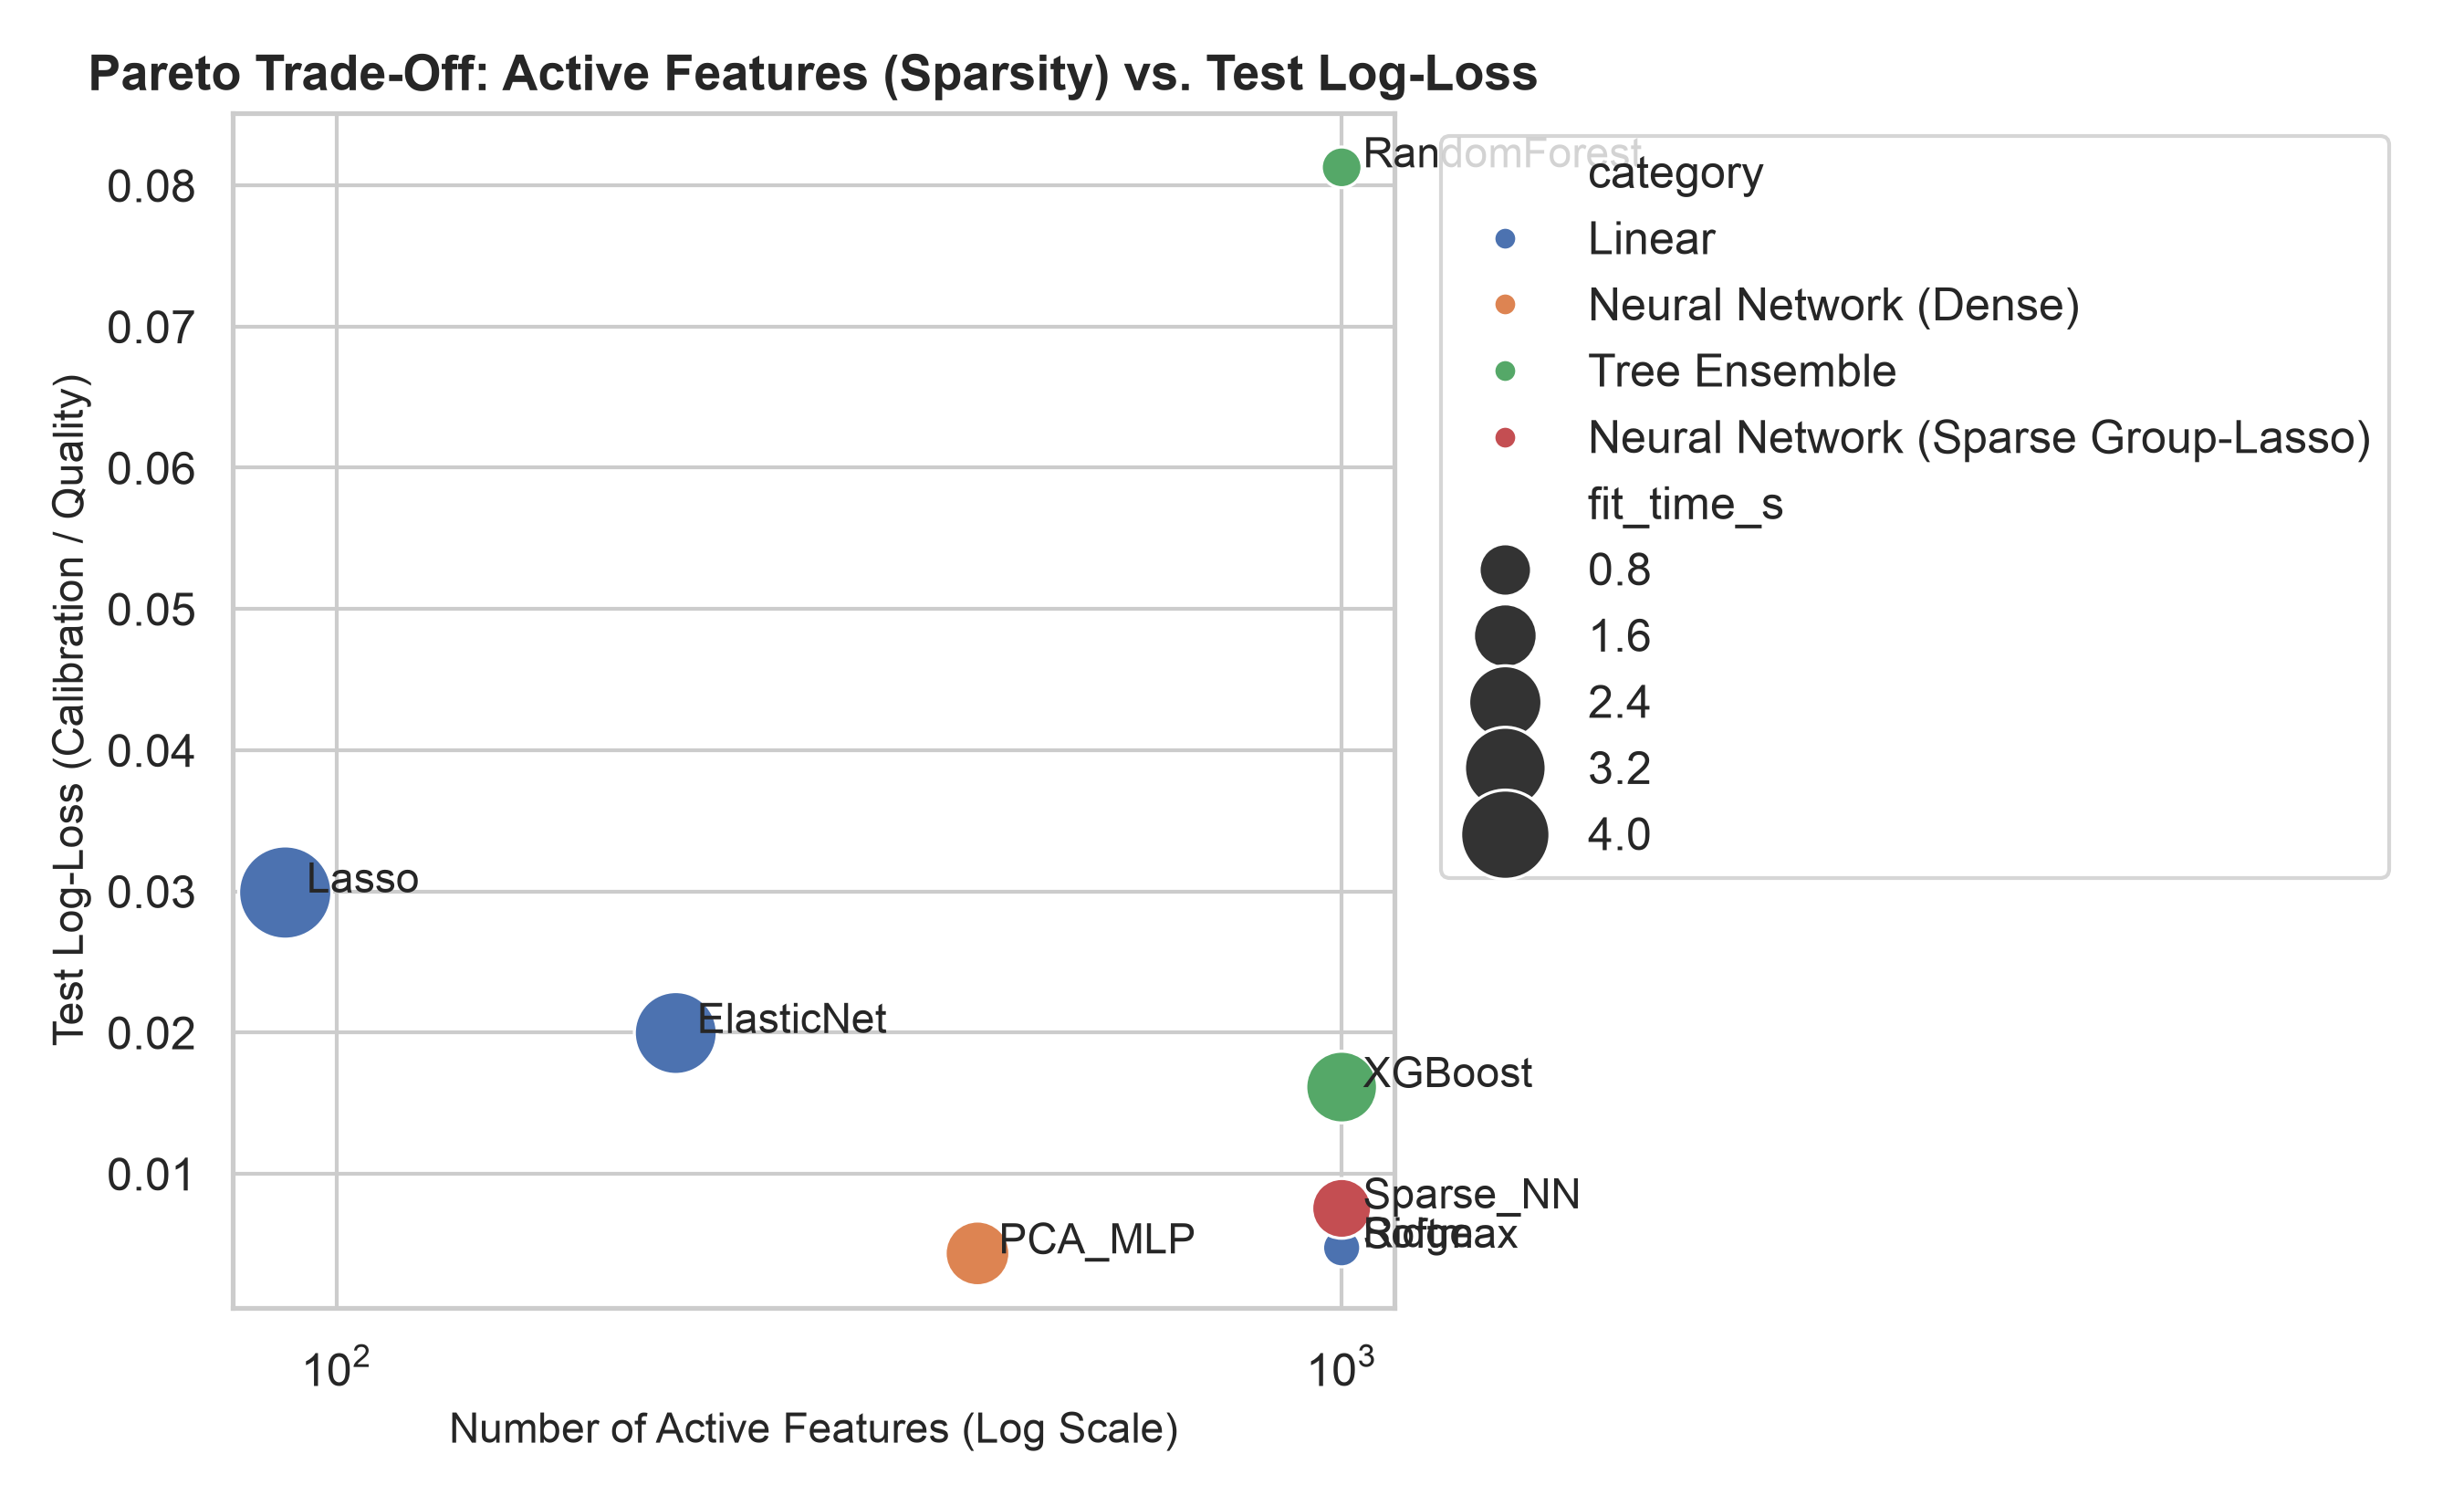

=== 05_pca_pc1_pc2.png ===


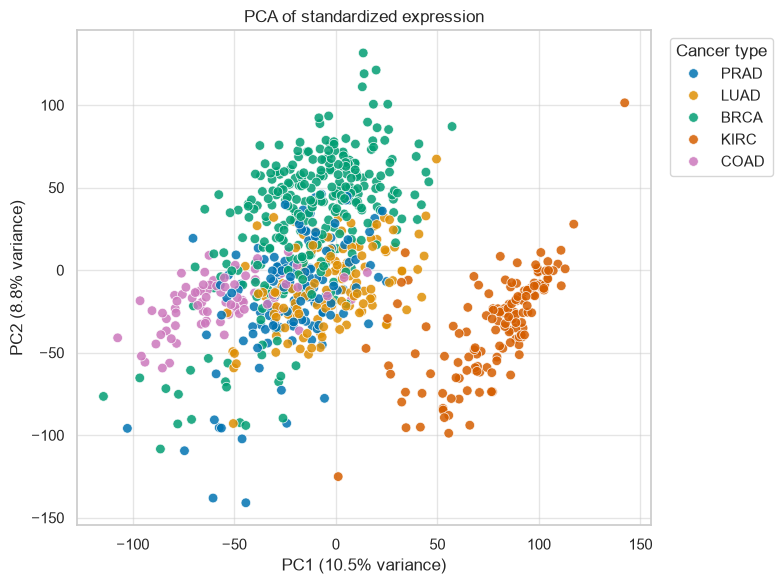

=== 06_top_variable_feature_heatmap.png ===


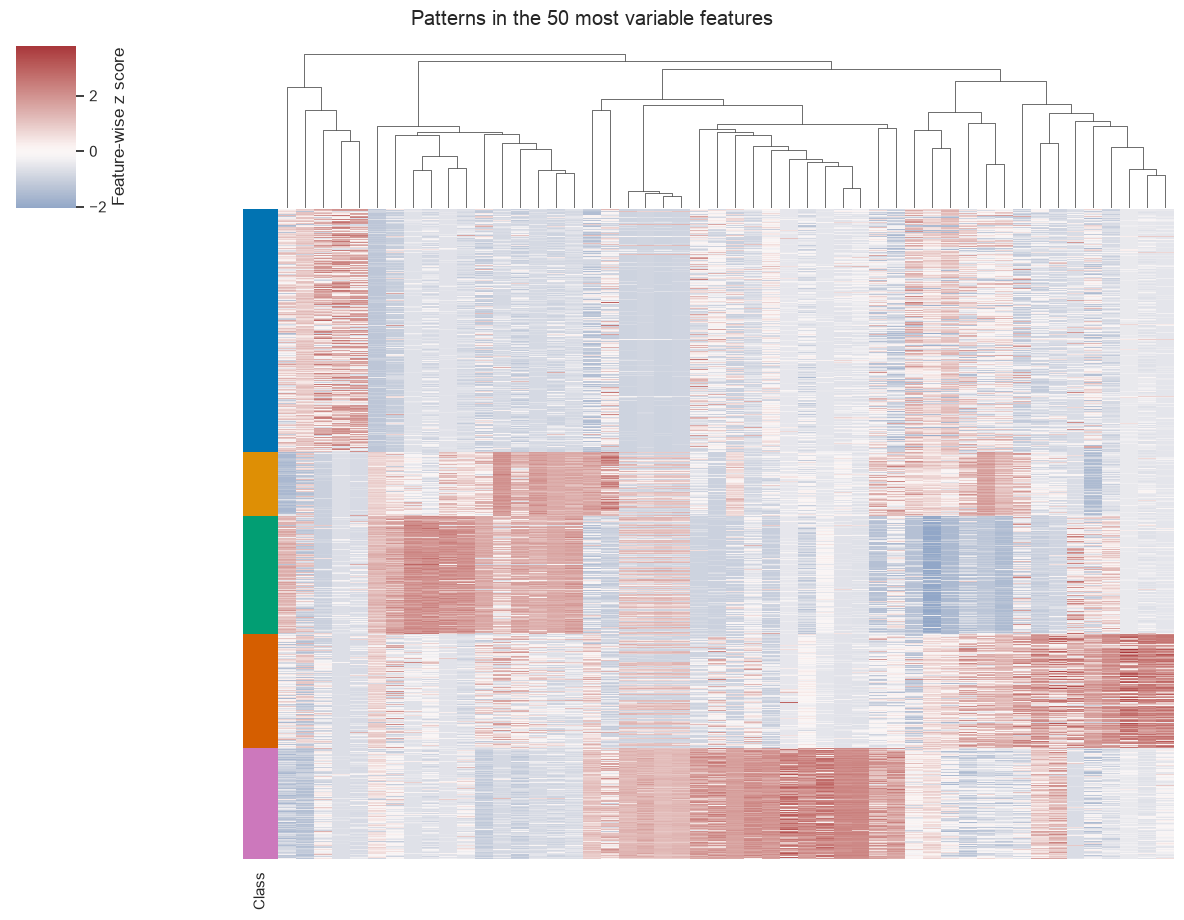

=== 07_sample_similarity_by_class.png ===


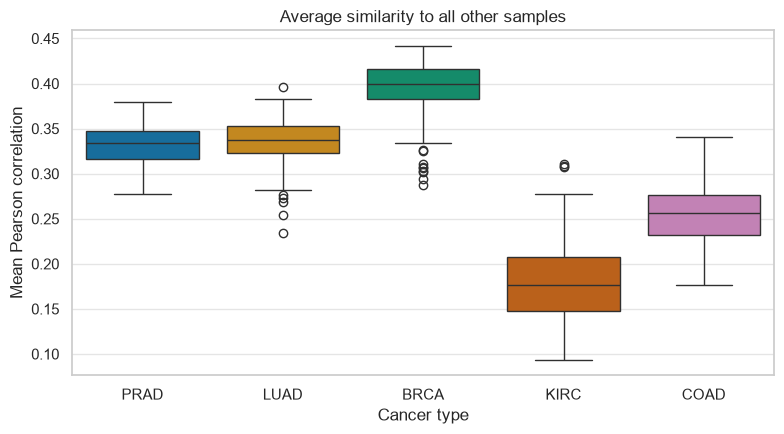

In [5]:
from IPython.display import Image, display
for p in sorted(FIGURES_DIR.glob('*.png')):
    print(f'=== {p.name} ===')
    display(Image(filename=str(p)))
